In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:
import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)

# 1. Data loading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

testset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

classes = (
    "plane", "car", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
)

# 2. Define network parameters
Din = 3 * 32 * 32  # Input size
H = 100           # Hidden-layer size
K = 10            # Output size

std = 0.01

w1 = torch.randn(Din, H) * std
b1 = torch.zeros(H)

w2 = torch.randn(H, K) * std
b2 = torch.zeros(K)

iterations = 10
lr = 0.1
lr_decay = 0.9
reg = 0.0

loss_history = []

# 3. Training loop
for t in range(iterations):
    running_loss = 0.0

    for i, data in enumerate(trainloader, 0):
        inputs, labels = data

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        y_train_onehot = nn.functional.one_hot(
            labels, K
        ).float()

        z1 = x_train.mm(w1) + b1
        hidden = torch.sigmoid(z1)

        y_pred = hidden.mm(w2) + b2

        log_probs = y_pred - torch.logsumexp(
            y_pred,
            dim=1,
            keepdim=True
        )
        probs = torch.exp(log_probs)

        loss = (
            -(1.0 / Ntr) * torch.sum(y_train_onehot * log_probs)
            + reg * (
                torch.sum(w1**2) + torch.sum(w2**2)
            )
        )

        loss_history.append(loss.item())
        running_loss += loss.item()


        # Derivative of softmax + cross-entropy
        dy_pred = (probs - y_train_onehot) / Ntr

        # Output-layer gradients
        dw2 = hidden.t().mm(dy_pred) + 2.0 * reg * w2
        db2 = dy_pred.sum(dim=0)

        # Gradient through hidden layer
        dhidden = dy_pred.mm(w2.t())

        # Sigmoid derivative
        dz1 = dhidden * hidden * (1.0 - hidden)

        # Input-to-hidden layer gradients
        dw1 = x_train.t().mm(dz1) + 2.0 * reg * w1
        db1 = dz1.sum(dim=0)

        w1 -= lr * dw1
        b1 -= lr * db1

        w2 -= lr * dw2
        b2 -= lr * db2

    # Print mean loss for each epoch
    print(
        f"Epoch {t + 1}/{iterations}, "
        f"Loss: {running_loss / len(trainloader):.4f}"
    )

    # Learning-rate decay
    lr *= lr_decay

# 4. Plotting the loss history
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration (mini-batch)")
plt.ylabel("Cross-Entropy Loss")
plt.show()

# 5. Calculate accuracy on training set
correct_train = 0
total_train = 0

with torch.no_grad():
    for data in trainloader:
        inputs, labels = data

        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)

        # Forward pass
        hidden_train = torch.sigmoid(x_train.mm(w1) + b1)
        y_train_pred = hidden_train.mm(w2) + b2

        predicted_train = torch.argmax(y_train_pred, dim=1)

        total_train += labels.size(0)
        correct_train += (
            predicted_train == labels
        ).sum().item()

train_acc = 100.0 * correct_train / total_train

print(f"Training accuracy: {train_acc:.2f}%")

# 6. Calculate accuracy on test set
correct_test = 0
total_test = 0

with torch.no_grad():
    for data in testloader:
        inputs, labels = data

        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)

        # Forward pass
        hidden_test = torch.sigmoid(x_test.mm(w1) + b1)
        y_test_pred = hidden_test.mm(w2) + b2

        predicted_test = torch.argmax(y_test_pred, dim=1)

        total_test += labels.size(0)
        correct_test += (
            predicted_test == labels
        ).sum().item()

test_acc = 100.0 * correct_test / total_test

print(f"Test accuracy: {test_acc:.2f}%")

Using device: cpu


100%|██████████| 9.91M/9.91M [00:01<00:00, 5.85MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 154kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.46MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.46MB/s]


LeNet5(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (pool): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (conv3): Conv2d(16, 120, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=120, out_features=84, bias=True)
  (fc2): Linear(in_features=84, out_features=10, bias=True)
  (activation): Tanh()
)
Epoch 1/10, Loss: 0.2342
Epoch 2/10, Loss: 0.0684
Epoch 3/10, Loss: 0.0488
Epoch 4/10, Loss: 0.0390
Epoch 5/10, Loss: 0.0312
Epoch 6/10, Loss: 0.0260
Epoch 7/10, Loss: 0.0218
Epoch 8/10, Loss: 0.0196
Epoch 9/10, Loss: 0.0170
Epoch 10/10, Loss: 0.0138

Results after 10 epochs:
Training accuracy: 99.59%
Test accuracy: 98.74%


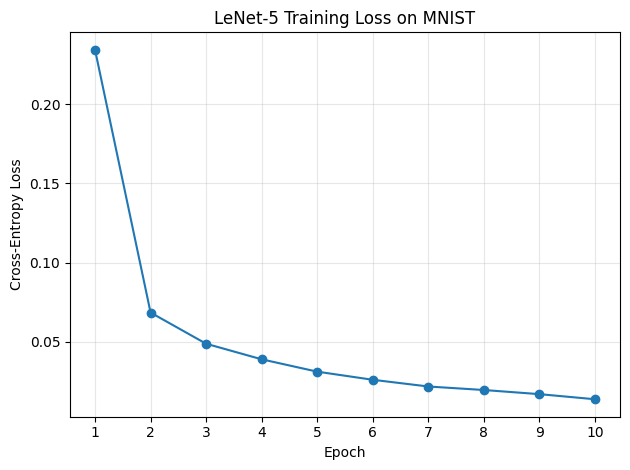

In [3]:
import torch.optim as optim
import matplotlib.pyplot as plt

torch.manual_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
print(f"Using device: {device}")

# 1. Data loading
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

batch_size = 64

trainset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

testset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

# 2. Define LeNet-5
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()

        # Input: 1 x 32 x 32
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=6,
            kernel_size=5
        )  # Output: 6 x 28 x 28

        self.pool = nn.AvgPool2d(
            kernel_size=2,
            stride=2
        )

        self.conv2 = nn.Conv2d(
            in_channels=6,
            out_channels=16,
            kernel_size=5
        )  # After first pooling: 16 x 10 x 10

        self.conv3 = nn.Conv2d(
            in_channels=16,
            out_channels=120,
            kernel_size=5
        )  # After second pooling: 120 x 1 x 1

        self.fc1 = nn.Linear(120, 84)
        self.fc2 = nn.Linear(84, 10)

        self.activation = nn.Tanh()

    def forward(self, x):
        x = self.activation(self.conv1(x))
        x = self.pool(x)

        x = self.activation(self.conv2(x))
        x = self.pool(x)

        x = self.activation(self.conv3(x))
        x = torch.flatten(x, start_dim=1)

        x = self.activation(self.fc1(x))
        x = self.fc2(x)

        # Return logits; CrossEntropyLoss includes log-softmax.
        return x


model = LeNet5().to(device)
print(model)

# 3. Loss function and optimizer
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 10
loss_history = []

# 4. Training loop
for epoch in range(epochs):
    model.train()

    running_loss = 0.0
    total_samples = 0

    for inputs, labels in trainloader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation and parameter update
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        total_samples += labels.size(0)

    epoch_loss = running_loss / total_samples
    loss_history.append(epoch_loss)

    print(
        f"Epoch {epoch + 1}/{epochs}, "
        f"Loss: {epoch_loss:.4f}"
    )

# 5. Calculate accuracy
def calculate_accuracy(model, loader):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    return 100.0 * correct / total


# Evaluate the final model after all 10 epochs
train_acc = calculate_accuracy(model, trainloader)
test_acc = calculate_accuracy(model, testloader)

print(f"\nResults after {epochs} epochs:")
print(f"Training accuracy: {train_acc:.2f}%")
print(f"Test accuracy: {test_acc:.2f}%")

# 6. Plot training loss
plt.plot(
    range(1, epochs + 1),
    loss_history,
    marker="o"
)
plt.title("LeNet-5 Training Loss on MNIST")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.xticks(range(1, epochs + 1))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()